In [47]:
import xarray as xr
from sklearn.model_selection import train_test_split, LeaveOneGroupOut, cross_val_score, cross_val_predict, GridSearchCV
from sklearn.metrics import mean_absolute_error, root_mean_squared_error
import xgboost as xgb
from xgboost import plot_importance
from xarray import DataArray, Dataset
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import rioxarray 
from shapely.geometry import Polygon, Point
import csv



In [48]:
range_id = 1

In [51]:
silo = xr.open_dataset(f"/scratch/tm70/ag9761/iceds_datasets/silo_monthly_rain_iceds_{range_id}_processed.nc")
gcms = xr.open_dataset(f"/scratch/tm70/ag9761/iceds_datasets/preprocessed_dataset_{range_id}.nc")

In [52]:
silo

<xarray.Dataset> Size: 30MB
Dimensions:    (time: 288, latitude: 126, longitude: 104)
Coordinates:
  * time       (time) datetime64[ns] 2kB 1993-01-01 1993-02-01 ... 2016-12-01
  * latitude   (latitude) float64 1kB -30.15 -30.1 -30.05 ... -24.0 -23.95 -23.9
  * longitude  (longitude) float64 832B 148.8 148.9 148.9 ... 153.9 153.9 154.0
Data variables:
    pr         (time, latitude, longitude) float64 30MB ...
Attributes: (12/16)
    CDI:                      Climate Data Interface version 2.4.3 (https://m...
    Conventions:              CF-1.6
    institution:              Queensland Government, Department of Environmen...
    department:               Department of Environment and Science
    department_short:         DES
    copyright:                Copyright - the State of Queensland Department ...
    ...                       ...
    reference:                Jeffrey, S.J., Carter, J.O., Moodie, K.B.A. and...
    disclaimer:               1. The user accepts all responsibility and risk...
    history:                  Wed Apr 22 17:32:41 2026: cdo mergetime 1993.mo...
    CDO:                      Climate Data Operators version 2.4.3 (https://m...
    standard_name:            time
    axis:                     T

# Preprocessing 
### Selecting Coords

In [6]:
def single_point_data_analysis():
 
    fig, axes = plt.subplots(nrows=2, ncols=2, figsize = (10,10),sharey=True)
    for idx, model in enumerate([silo, gcms.sel(model="ecmwf", lead=0), gcms.sel(model="access", lead=0), gcms.sel(model="ukmo", lead=0)]):
        j = idx % 2
        i = idx // 2
        ax = sns.histplot(model["pr"], ax=axes[i, j])

In [41]:
rows = []

In [7]:
is_single_point = True
grid_point = (np.float64(-29.0), np.float64(150.0))
model_radius = 0.0
silo_radius = 0.25
n_points_inner_circle = 6
radius_inner_circle = 0.6
n_points_outer_circle = 6
radius_outer_circle = 1.04

In [8]:
def construct_circle(origin, n_points, radius, base_angle=0.0, include_origin=False):

    def get_circular_point(angle):
        print(angle)
        return (round(origin[0] + radius * xr.ufuncs.cos(angle), 2), round(origin[1] + radius * xr.ufuncs.sin(angle), 2))
    
    coords = [get_circular_point(base_angle + 2 * i * np.pi / n_points_inner_circle) for i in range(n_points)]
    if include_origin:
        coords.insert(len(coords) // 2, origin)

    return tuple(map(list, zip(*coords)))

construct_circle(grid_point, n_points_inner_circle, radius_inner_circle)
construct_circle(grid_point, n_points_outer_circle, radius_outer_circle, base_angle=np.pi / 8, include_origin=True)

0.0
1.0471975511965976
2.0943951023931953
3.141592653589793
4.1887902047863905
5.235987755982989
0.39269908169872414
1.4398966328953218
2.4870941840919194
3.5342917352885173
4.581489286485114
5.6286868376817125


([np.float64(-28.04),
  np.float64(-28.86),
  np.float64(-29.83),
  np.float64(-29.0),
  np.float64(-29.96),
  np.float64(-29.14),
  np.float64(-28.17)],
 [np.float64(150.4),
  np.float64(151.03),
  np.float64(150.63),
  np.float64(150.0),
  np.float64(149.6),
  np.float64(148.97),
  np.float64(149.37)])

In [9]:
if is_single_point:

    gcms = gcms.sel(latitude=slice(grid_point[0] - model_radius, grid_point[0] + model_radius), longitude=slice(grid_point[1] - model_radius, grid_point[1] + model_radius))

    ## Chebyshev
    # chebyshev_dist = np.maximum(abs(silo["latitude"] - grid_point[0]), abs(silo["longitude"] - grid_point[1]))
    # mask = xr.DataArray(np.isclose(chebyshev_dist, silo_radius) | np.isclose(chebyshev_dist, 0.0), dims = chebyshev_dist.dims, coords = chebyshev_dist.coords)
    # silo = silo.where(mask, drop=True)
    ## Knight
    # offsets = [(1,2),(2,1),(2,-1),(1,-2),(0,0),(-1,-2),(-2,-1),(-2,1),(-1,2)]
    # lat_points = [round(round(round(grid_point[0] + di*0.6, 2) * 20) / 20, 2) for di, _ in offsets]
    # lon_points = [round(round(round(grid_point[1] + dj*0.6, 2) * 20) / 20, 2) for _, dj in offsets]
    # points = [(round(round(round(grid_point[0] + di*0.6, 2) * 20) / 20, 2), round(grid_point[1] + dj*0.6, 2)) for di, dj in offsets]
    # silo["latitude"] = silo["latitude"].round(2)
    # silo["longitude"] = silo["longitude"].round(2)
    # silo = silo.stack(z=("latitude", "longitude")).sel(z=points).unstack()
    # print(points)
    ## Inner circle
    points_1 = construct_circle(grid_point, n_points_inner_circle, radius_inner_circle, include_origin=True)
    points_2 = construct_circle(grid_point, n_points_outer_circle, radius_outer_circle, base_angle=np.pi / 6)
    points = (points_1[0] + points_2[0], points_1[1] + points_2[1])
    # points = points_1
    print(points[0])
    print(points[1])
    print(len(points[0]))
    lat_da = xr.DataArray(points[0], dims="point")
    lon_da = xr.DataArray(points[1], dims="point")

    silo = silo.sel(latitude=lat_da, longitude=lon_da, method="nearest")
    # silo_temp = silo_temp.assign_coords(latitude=("point", ),
    #                                     longitude=("point", silo_temp.longitude.values))
    silo = silo.assign_coords(point=pd.MultiIndex.from_arrays([silo.latitude.values, silo.longitude.values], names=["latitude", "longitude"])).unstack("point")
    silo = silo.sortby(["latitude", "longitude"])

    # silo = silo.sel(latitude=lat_points, longitude=lon_points, method="nearest").drop_duplicates(dim=["latitude", "longitude"])
    # silo = silo.stack(z=("latitude", "longitude")).sel(z=points).unstack()
    # silo = silo.sortby(["latitude", "longitude"])




0.0
1.0471975511965976
2.0943951023931953
3.141592653589793
4.1887902047863905
5.235987755982989
0.5235987755982988
1.5707963267948966
2.617993877991494
3.665191429188092
4.71238898038469
5.759586531581288
[np.float64(-28.4), np.float64(-28.7), np.float64(-29.3), np.float64(-29.0), np.float64(-29.6), np.float64(-29.3), np.float64(-28.7), np.float64(-28.1), np.float64(-29.0), np.float64(-29.9), np.float64(-29.9), np.float64(-29.0), np.float64(-28.1)]
[np.float64(150.0), np.float64(150.52), np.float64(150.52), np.float64(150.0), np.float64(150.0), np.float64(149.48), np.float64(149.48), np.float64(150.52), np.float64(151.04), np.float64(150.52), np.float64(149.48), np.float64(148.96), np.float64(149.48)]
13


/scratch/tm70/ag9761/tmp/ipykernel_1628048/1079926331.py:32: FutureWarning: the `pandas.MultiIndex` object(s) passed as 'point' coordinate(s) or data variable(s) will no longer be implicitly promoted and wrapped into multiple indexed coordinates in the future (i.e., one coordinate for each multi-index level + one dimension coordinate). If you want to keep this behavior, you need to first wrap it explicitly using `mindex_coords = xarray.Coordinates.from_pandas_multiindex(mindex_obj, 'dim')` and pass it as coordinates, e.g., `xarray.Dataset(coords=mindex_coords)`, `dataset.assign_coords(mindex_coords)` or `dataarray.assign_coords(mindex_coords)`.
  silo = silo.assign_coords(point=pd.MultiIndex.from_arrays([silo.latitude.values, silo.longitude.values], names=["latitude", "longitude"])).unstack("point")


In [10]:
silo["pr"].isel(time=1).values

array([[       nan, 1.575     ,        nan, 2.38571429,        nan],
       [       nan,        nan, 2.13214286,        nan,        nan],
       [       nan, 1.86428571,        nan, 2.05      ,        nan],
       [2.40357143,        nan, 3.82142857,        nan, 2.07142857],
       [       nan, 1.875     ,        nan, 1.75357143,        nan],
       [       nan,        nan, 1.52142857,        nan,        nan],
       [       nan, 2.07142857,        nan, 1.69285714,        nan]])

/scratch/tm70/ag9761/tmp/ipykernel_1628048/3060954924.py:7: FutureWarning: In a future version of xarray the default value for join will change from join='outer' to join='exact'. This change will result in the following ValueError: cannot be aligned with join='exact' because index/labels/sizes are not equal along these coordinates (dimensions): 'latitude' ('latitude',) The recommendation is to set join explicitly for this case.
  scatter_plot_data = xr.merge([model, silo.rename_vars({"pr" : "obs_pr"})], compat="override")
/scratch/tm70/ag9761/tmp/ipykernel_1628048/3060954924.py:7: FutureWarning: In a future version of xarray the default value for join will change from join='outer' to join='exact'. This change will result in the following ValueError: cannot be aligned with join='exact' because index/labels/sizes are not equal along these coordinates (dimensions): 'longitude' ('longitude',) The recommendation is to set join explicitly for this case.
  scatter_plot_data = xr.merge([model,

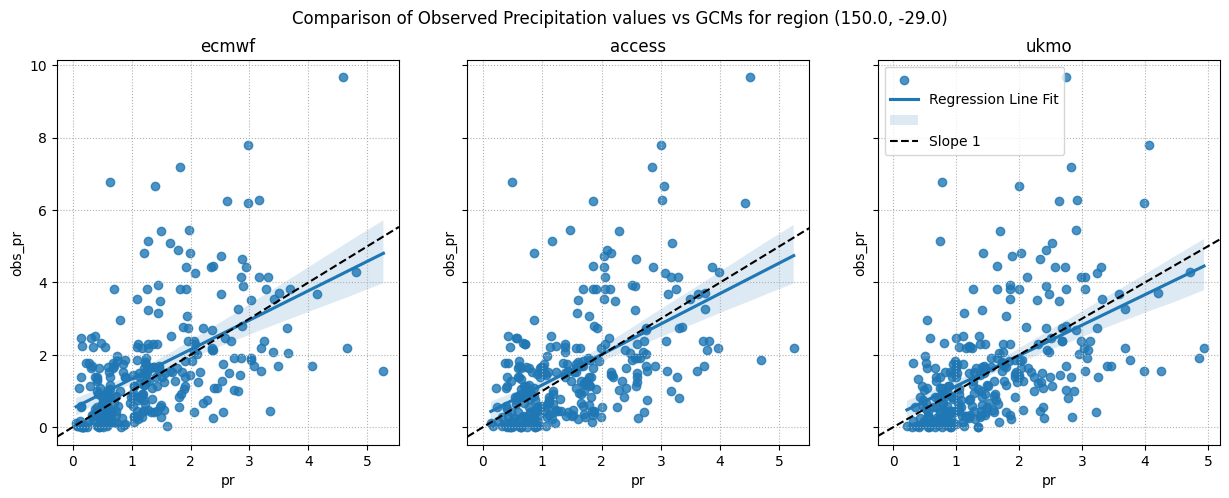

In [11]:
def single_point_data_analysis():
 
    fig, axes = plt.subplots(nrows=1, ncols=3, figsize = (15,5),sharey=True)
    fig.suptitle("Comparison of Observed Precipitation values vs GCMs for region (150.0, -29.0)")
    for idx, model in enumerate([gcms.sel(model="ecmwf", lead=0), gcms.sel(model="access", lead=0), gcms.sel(model="ukmo", lead=0)]):

        scatter_plot_data = xr.merge([model, silo.rename_vars({"pr" : "obs_pr"})], compat="override")
        ax = sns.regplot(scatter_plot_data.to_dataframe(), x="pr", y="obs_pr", ax=axes[idx])
        ax.axline((0, 0), slope=1, color='k', ls='--')
        plt.legend(loc='upper left', labels=[None, "Regression Line Fit", None, "Slope 1"])
        ax.grid(True, axis='both', ls=':')
        ax.set_title(model.model.values)

single_point_data_analysis()
plt.show()

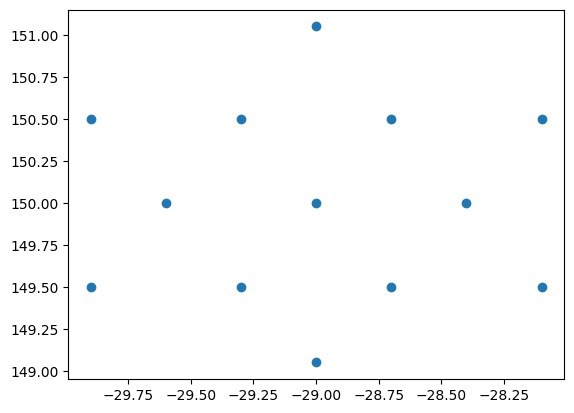

In [12]:
silo_stacked = silo.isel(time=0)["pr"].stack(x=['latitude','longitude'])
silo_df = silo_stacked[silo_stacked.notnull()].to_dataframe().reset_index()
plt.scatter(silo_df["latitude"], silo_df["longitude"])

### Data Analysis

# Feature Engineering

In [13]:
class FeatureEngineering:

    def __init__(self, ds: Dataset, lead_months = 6, window_time = 0):
        self.window_time = window_time
        self.ds = ds.copy()
        self.ds = self.ds.isel(lead=slice(0, lead_months))
        self._process_dates()
    

    def _process_dates(self):
        self.ds["month"] = self.ds["time"].dt.month
        self.ds["year"] = self.ds["time"].dt.year

    def enable_climate_classification(self):
        # https://doi.org/10.1038/s41597-023-02549-6
        climate_class_ds = rioxarray.open_rasterio("koppen_geiger_0p00833333.tif")
        climate_class_ds = climate_class_ds.rename({"x": "longitude", "y": "latitude"})
        climate_class_ds = climate_class_ds.squeeze("band").drop_vars(["band", "spatial_ref"])

        classification = climate_class_ds.sel(latitude=self.ds.latitude, longitude=self.ds.longitude, method="nearest")
        classification = classification.reindex_like(self.ds, method="nearest")
        self.ds["classification"] = classification

    def enable_wet_season_feature(self):
        """Binary switch for dry/wet season"""
        wet_months = [10, 11, 12, 1, 2, 3]
        self.ds["is_wet_month"] = (self.ds["time"].dt.month.isin(wet_months)).astype(int)
    
    def create_lead_time_features(self, params: list[str]):
        for param in params:
            param_features = self._create_lead_time_features(param)
            self.ds = self.ds.drop_vars([param])
            self.ds = xr.merge([self.ds, param_features], join="outer")
        self.ds = self.ds.drop_vars(["lead", "model"])
        return self.ds

    def _create_lead_time_features(self, param: str) -> Dataset:
        """Have separate columns for each lead time forecast."""
        
        param_lead_time = (
            self.ds[param]
            .stack(lead_model=("lead", "model"))
            .groupby("lead_model")
            .map(lambda da: da.squeeze(drop=True))
            .to_dataset(dim="lead_model")
        )

        return param_lead_time.rename_vars({
            k: f"{k[1]}_{k[0]}_{param}"
            for k in param_lead_time.data_vars
        })
    
    def add_obs_window_time(self, period: int):
        for i in range(period):
            self.ds[f"window_{period - 1}"] = silo["pr"].shift(time=period)
    
    # TODO: Add climatology feature

feature_dataset = FeatureEngineering(gcms, lead_months=1) 
# feature_dataset.enable_wet_season_feature()
# feature_dataset.enable_climate_classification()
feature_dataset.create_lead_time_features(["pr"])
# feature_dataset.add_obs_window_time(period=1)

<xarray.Dataset> Size: 11kB
Dimensions:      (latitude: 1, longitude: 1, time: 293)
Coordinates:
  * latitude     (latitude) float64 8B -29.0
  * longitude    (longitude) float64 8B 150.0
  * time         (time) datetime64[ns] 2kB 1993-01-01 1993-02-01 ... 2017-05-01
Data variables:
    month        (time) int64 2kB 1 2 3 4 5 6 7 8 9 10 ... 9 10 11 12 1 2 3 4 5
    year         (time) int64 2kB 1993 1993 1993 1993 ... 2017 2017 2017 2017
    ecmwf_0_pr   (time) float32 1kB 2.455 1.259 0.7334 0.1787 ... nan nan nan
    ukmo_0_pr    (time) float32 1kB nan 1.274 0.8459 0.5467 ... nan nan nan nan
    access_0_pr  (time) float32 1kB 2.41 1.905 0.5982 0.4842 ... nan nan nan nan
Attributes:
    GRIB_edition:            1
    GRIB_centre:             ecmf
    GRIB_centreDescription:  European Centre for Medium-Range Weather Forecasts
    GRIB_subCentre:          0
    Conventions:             CF-1.7
    institution:             European Centre for Medium-Range Weather Forecasts

In [14]:
dataset = xr.merge([feature_dataset.ds, silo], join="outer")

In [15]:
dataset

<xarray.Dataset> Size: 93kB
Dimensions:      (latitude: 7, longitude: 5, time: 293)
Coordinates:
  * latitude     (latitude) float64 56B -29.9 -29.6 -29.3 ... -28.7 -28.4 -28.1
  * longitude    (longitude) float64 40B 149.1 149.5 150.0 150.5 151.1
  * time         (time) datetime64[ns] 2kB 1993-01-01 1993-02-01 ... 2017-05-01
Data variables:
    month        (time) int64 2kB 1 2 3 4 5 6 7 8 9 10 ... 9 10 11 12 1 2 3 4 5
    year         (time) int64 2kB 1993 1993 1993 1993 ... 2017 2017 2017 2017
    ecmwf_0_pr   (time) float32 1kB 2.455 1.259 0.7334 0.1787 ... nan nan nan
    ukmo_0_pr    (time) float32 1kB nan 1.274 0.8459 0.5467 ... nan nan nan nan
    access_0_pr  (time) float32 1kB 2.41 1.905 0.5982 0.4842 ... nan nan nan nan
    pr           (time, latitude, longitude) float64 82kB nan 1.574 ... nan nan
Attributes:
    GRIB_edition:            1
    GRIB_centre:             ecmf
    GRIB_centreDescription:  European Centre for Medium-Range Weather Forecasts
    GRIB_subCentre:          0
    Conventions:             CF-1.7
    institution:             European Centre for Medium-Range Weather Forecasts

In [16]:
dataset = dataset.sel(time=slice("1993-01-01", "2016-12-31"))

In [17]:
dataset = dataset.to_dataframe().sort_values(by=['time', "latitude", "longitude"])
if silo_radius > 0:
    rounded_index = pd.MultiIndex.from_tuples(
        [(round(t[0]), round(t[1]), t[2]) for t in dataset.index],
        names=dataset.index.names
    )
    dataset.index = rounded_index

In [18]:
dataset = dataset.dropna(subset=["pr"]) # Could be because points selected before outer merge could be Nan

In [19]:
# TODO: Can be better within feature engineering, then drop NaN rows after creating dataframe 
# dataset = dataset.set_index(["year", "month"]).reset_index()
dataset = dataset.reset_index().drop(columns=["time"])

In [20]:
# xr.ufuncs.log(1 + dataset["pr"])
dataset["pr"] = np.log(dataset["pr"] + 1)

In [21]:
# Temp operations
dataset = dataset[dataset["month"].isin([10, 11, 12, 1, 2, 3])]
# dataset = pd.get_dummies(dataset, columns=["month"], dtype=int)
dataset = dataset.drop(columns=["month", "latitude", "longitude"]) 

In [25]:
dataset

,year,ecmwf_0_pr,ukmo_0_pr,access_0_pr,pr
0,1993,2.455219,NaN,2.410054,0.945536
1,1993,2.455219,NaN,2.410054,1.514773
2,1993,2.455219,NaN,2.410054,0.782575
3,1993,2.455219,NaN,2.410054,0.880831
4,1993,2.455219,NaN,2.410054,0.811647
...,...,...,...,...,...
3739,2016,1.099367,2.049223,2.521639,0.900686
3740,2016,1.099367,2.049223,2.521639,1.180143
3741,2016,1.099367,2.049223,2.521639,1.379010
3742,2016,1.099367,2.049223,2.521639,0.704374


# Training XGBoost Model

In [23]:
is_yearly_split = True
X = dataset.drop(columns=["pr"])
y = dataset["pr"]
X
y

0       0.945536
1       1.514773
2       0.782575
3       0.880831
4       0.811647
          ...   
3739    0.900686
3740    1.180143
3741    1.379010
3742    0.704374
3743    0.936726
Name: pr, Length: 1872, dtype: float64

In [24]:
def get_xgboost_model():
    xgb_model = xgb.XGBRegressor(objective='reg:squarederror', eval_metric= 'mae', max_depth=5, eta=0.1, 
                             subsample=0.7, colsample_bytree=0.7)

    return xgb_model

def xgboost_train(X_train, y_train):
    params = {
        'objective': 'reg:squarederror',
        'eval_metric': 'mae',
        'max_depth': 5,
        'eta': 0.1,
        'subsample': 0.7,
        'colsample_bytree': 0.7,
        'verbosity': 0
    }

    xgb_model = get_xgboost_model()

    xgb_model.fit(X_train, y_train)

    return xgb_model


def xgboost_predict(xgb_model):
    return xgb_model.predict(X_test)

In [26]:
if is_yearly_split:
    logo = LeaveOneGroupOut()
    groups = dataset["year"]
    
    xgb_model = xgb.XGBRegressor(objective='reg:squarederror')

    y_pred = np.empty(0, dtype=float)

    param_grid = {
        'learning_rate': [0.01, 0.05, 0.1, 0.2],
        'max_depth': [2],
        'min_child_weight': [1, 3],
        'subsample': [0.2, 0.3, 0.4, 0.7],
        'colsample_bytree': [0.7], 
        'reg_alpha': [1.0],          # L1 regularization
        'reg_lambda': [5.0],         # L2 regularization (increase this)
        'eta': [0.1],
        'n_estimators': [5, 10, 20, 30, 50]
    }

    for train_idx, val_idx in logo.split(X, y, groups):
        X_train, X_val = X.iloc[train_idx], X.iloc[val_idx]
        y_train, y_val = y.iloc[train_idx], y.iloc[val_idx]

        xgb_model = get_xgboost_model()
        clf_xgb_model = GridSearchCV(xgb_model, param_grid)


        clf_xgb_model.fit(X_train.drop(columns=["year"]), y_train) # Uses 5-fold cross validation

        y_val_pred = clf_xgb_model.predict(X_val.drop(columns=["year"]))
        # if silo_radius > 0.0:
        #     y_val_pred = y_val_pred[4::9]  # Select only middle points
        #     print(len(y_val_pred))

        print(clf_xgb_model.best_estimator_.feature_importances_)
        y_pred = np.append(y_pred, y_val_pred)
        importance = clf_xgb_model.best_params_

    
    y_pred = cross_val_predict(
        xgb_model,
        X.drop(columns=["year"]),
        y,
        groups=groups,
        cv=LeaveOneGroupOut(),
    )
        
else:
    X_train, X_test, y_train, y_test = train_test_split(
        X,
        y,
        test_size=0.05,
        shuffle=False
    )
    print(X_test)
    xgb_model = xgboost_train(X_train, y_train)

    y_pred = xgboost_predict(xgb_model)

[0.43296456 0.23801468 0.32902074]
[0.50137496 0.1627633  0.33586174]
[0.40917653 0.22897404 0.36184934]
[0.3917109  0.2765039  0.33178514]
[0.36725533 0.30687642 0.32586825]
[0.4083673  0.22742103 0.36421165]
[0.40928298 0.24452908 0.34618792]
[0.4175666  0.28389803 0.29853535]
[0.42521617 0.25879726 0.3159866 ]
[0.45643044 0.19275633 0.35081324]
[0.361658   0.25719306 0.3811489 ]
[0.22651653 0.31309116 0.4603923 ]
[0.4325363  0.24079566 0.32666802]
[0.33391157 0.08201792 0.58407056]
[0.53419363 0.1812133  0.28459305]
[0.3974387  0.28867975 0.31388158]
[0.42579043 0.2115694  0.36264014]
[0.465558   0.22040424 0.31403777]
[0.48437646 0.17776543 0.33785808]
[0.47032574 0.19447312 0.33520114]
[0.5776202  0.20511721 0.21726254]
[0.4374652  0.24045102 0.32208383]
[0.45096394 0.21820109 0.33083493]
[0.2516646  0.4446656  0.30366972]


# Evaluation

In [27]:
def single_point_data_analysis(data):
 
    fig, axes = plt.subplots(nrows=2, ncols=2, figsize = (10,10),sharey=True)
    fig.suptitle("Testing of Observed Precipitation values vs GCMs for region (150.0, -29.0)")
    for idx, model in enumerate(["ecmwf_0_pr", "ukmo_0_pr", "access_0_pr", "XGBoost"]):
    # for idx, model in enumerate(["ecmwf_0_pr", "access_0_pr", "XGBoost"]):
        i = idx // 2
        j = idx % 2

        ax = sns.regplot(data, x=model, y="obs_pr", ax=axes[i, j])
        ax.set(xlim=(0, 10))
        ax.axline((0, 0), slope=1, color='k', ls='--')
        plt.legend(loc='upper left', labels=[None, "Regression Line Fit", None, "Slope 1"])
        ax.grid(True, axis='both', ls=':')
        ax.set_title(model)

In [28]:
print(len(y_pred))

1872


In [29]:
y_pred

array([1.1722529 , 1.1722529 , 1.1722529 , ..., 0.91387576, 0.91387576,
       0.91387576], shape=(1872,), dtype=float32)

In [30]:
y_pred = np.exp(y_pred) - 1


In [31]:
y = np.exp(y) - 1


In [32]:
y_pred

array([2.2292597, 2.2292597, 2.2292597, ..., 1.4939699, 1.4939699,
       1.4939699], shape=(1872,), dtype=float32)

In [33]:
if is_yearly_split:
    testing = X.copy()
    testing["XGBoost"] = y_pred
    testing["obs_pr"] = y
    if silo_radius > 0:
        # idx = 8 * (round(silo_radius / 0.05)) + 1
        idx = len(points[0])
        print(idx)
        testing = testing[(idx//2)::idx]  # Select only middle points
        print(testing)
else:
    testing = X_test.copy()
    testing["XGBoost"] = y_pred
    testing["obs_pr"] = y_test


13
      year  ecmwf_0_pr  ukmo_0_pr  access_0_pr   XGBoost    obs_pr
6     1993    2.455219        NaN     2.410054  2.229260  1.087097
19    1993    1.259114   1.274306     1.905338  1.199254  3.821429
32    1993    0.733391   0.845947     0.598193  0.808312  0.854839
123   1993    1.274610   1.249790     1.577832  1.357213  2.177419
136   1993    2.061925   1.477732     1.875071  2.301076  0.410000
...    ...         ...        ...          ...       ...       ...
3607  2016    0.795865   2.234911     1.175717  0.942407  1.013793
3620  2016    0.619229   1.876659     1.596513  0.710809  0.225806
3711  2016    1.309718   2.141578     1.848841  1.065442  1.632258
3724  2016    1.490637   2.384980     2.001918  1.856537  0.556667
3737  2016    1.099367   2.049223     2.521639  1.493970  1.851613

[144 rows x 6 columns]


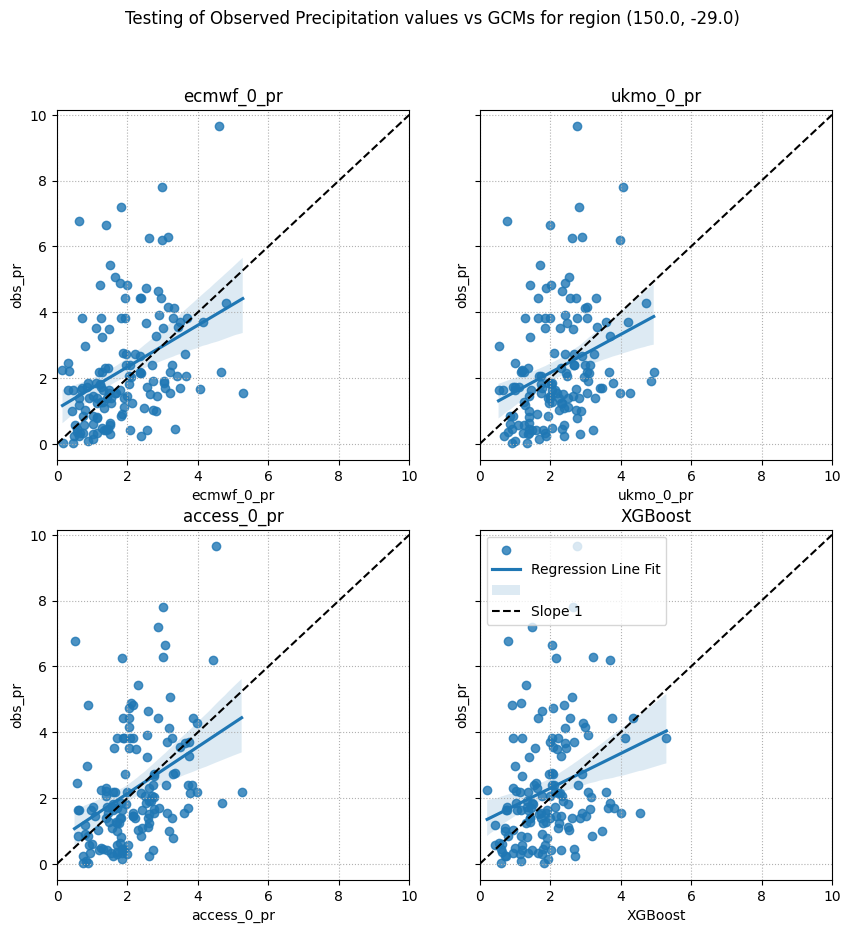

In [34]:
single_point_data_analysis(testing)

In [35]:
testing_temp = testing # .drop(testing.index[-4])
mask = ~np.isnan(testing["obs_pr"]) & ~np.isnan(testing["ukmo_0_pr"])
print(testing_temp["obs_pr"][mask])

model_mae = {
    "XGBoost" : mean_absolute_error(testing_temp["obs_pr"], testing_temp["XGBoost"]),
    "ecmwf" : mean_absolute_error(testing_temp["obs_pr"], testing_temp["ecmwf_0_pr"]),
    "ukmo" : mean_absolute_error(testing["obs_pr"][mask], testing["ukmo_0_pr"][mask]),
    "access" : mean_absolute_error(testing_temp["obs_pr"], testing_temp["access_0_pr"])
}

for model, mae in model_mae.items():
    print(f"{model} MAE: {mae}")

19      3.821429
32      0.854839
123     2.177419
136     0.410000
149     2.380645
          ...   
3607    1.013793
3620    0.225806
3711    1.632258
3724    0.556667
3737    1.851613
Name: obs_pr, Length: 143, dtype: float64
XGBoost MAE: 1.2879377689188471
ecmwf MAE: 1.2209314920935084
ukmo MAE: 1.3116210609057433
access MAE: 1.2438239765861563


In [38]:
model_rmse = {
    "XGBoost" : root_mean_squared_error(testing_temp["obs_pr"], testing_temp["XGBoost"]),
    "ecmwf" : root_mean_squared_error(testing_temp["obs_pr"], testing_temp["ecmwf_0_pr"]),
    "ukmo" : root_mean_squared_error(testing["obs_pr"][mask], testing["ukmo_0_pr"][mask]),
    "access" : root_mean_squared_error(testing_temp["obs_pr"], testing_temp["access_0_pr"])
}

for model, rmse in model_rmse.items():
    print(f"{model} RMSE: {rmse}")

XGBoost RMSE: 1.781301739043509
ecmwf RMSE: 1.7182114511358715
ukmo RMSE: 1.7311141906567438
access RMSE: 1.656307560080833


In [43]:
headers = ["Point", "XGBoost_mae", "ecmwf_mae", "ukmo_mae", "access_mae", "XGBoost_rmse", "ecmwf_rmse", "ukmo_rmse", "access_rmse"]
rows.append(
    [grid_point, model_mae["XGBoost"], model_mae["ecmwf"], model_mae["ukmo"], model_mae["access"], model_rmse["XGBoost"], model_rmse["ecmwf"], model_rmse["ukmo"], model_rmse["access"]]
)
# Note: 'newline=""' prevents blank lines between rows on Windows
with open('output.csv', mode='w', newline='', encoding='utf-8') as file:
    writer = csv.writer(file)
    
    writer.writerow(headers)   # Writes a single row (header)
    writer.writerows(rows)     # Writes multiple data rows at once

In [152]:
testing = y_test.to_frame()
# testing["pr_pred"] = y_pred

NameError: name 'y_test' is not defined

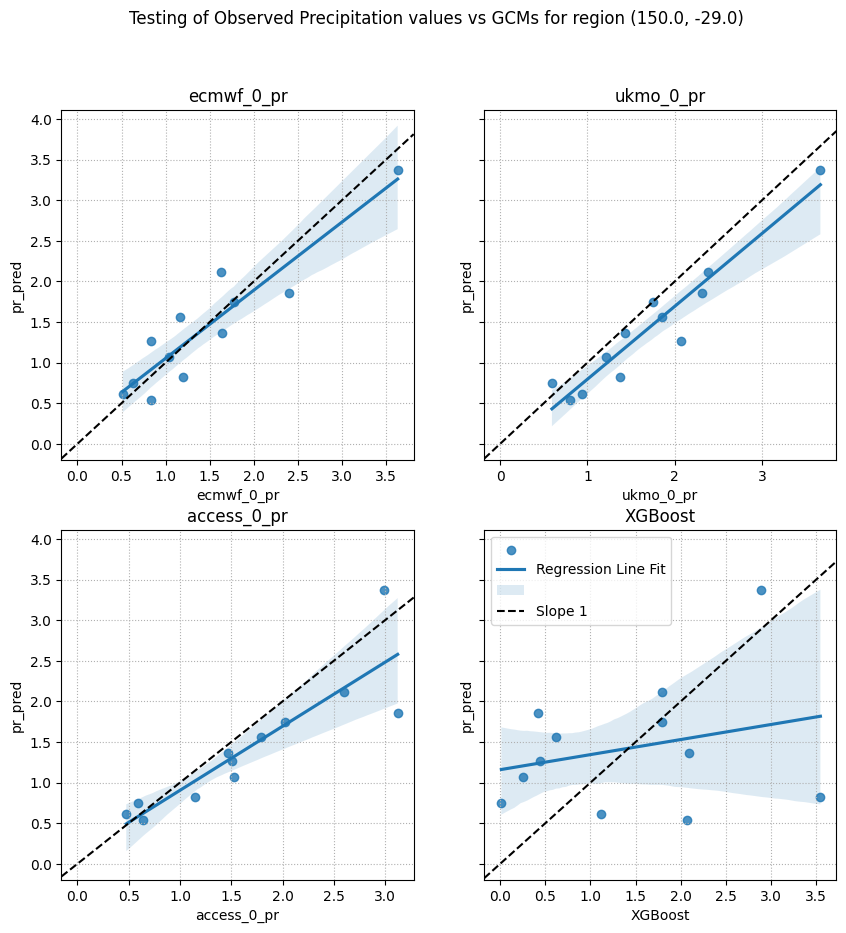

In [ ]:
data = X_test.copy()
data["XGBoost"] = y_pred
data["obs_pr"] = testing["pr"]

single_point_data_analysis(data)

In [28]:
def gcm_mae(pred_pr, obs_pr):
    df = obs_pr.copy()
    df["pred_pr"] = pred_pr
    print(df)
    return df.groupby(["latitude", "longitude"]).apply(lambda dt: mean_absolute_error(dt["pred_pr"], dt["obs_pr"]))

obs_pr = y_test.to_frame(name="obs_pr")
result = gcm_mae(y_pred, obs_pr).to_frame(name="XGBoost")

lead = 0
for model in ["ecmwf", "access", "ukmo"]:
    result[model] = gcm_mae(X_test[f"{model}_{lead}_pr"], obs_pr)
result

        obs_pr   pred_pr
4286  2.606452  1.633655
4287  2.477419  1.738277
4288  5.103333  3.416462
4289  6.656667  5.333120
4290  2.393333  4.073025
...        ...       ...
4507  1.912903  4.554993
4508  1.567742  2.899856
4509  1.851613  2.648596
4510  1.719355  2.518556
4511  1.248387  4.061213

[226 rows x 2 columns]


KeyError: 'latitude'

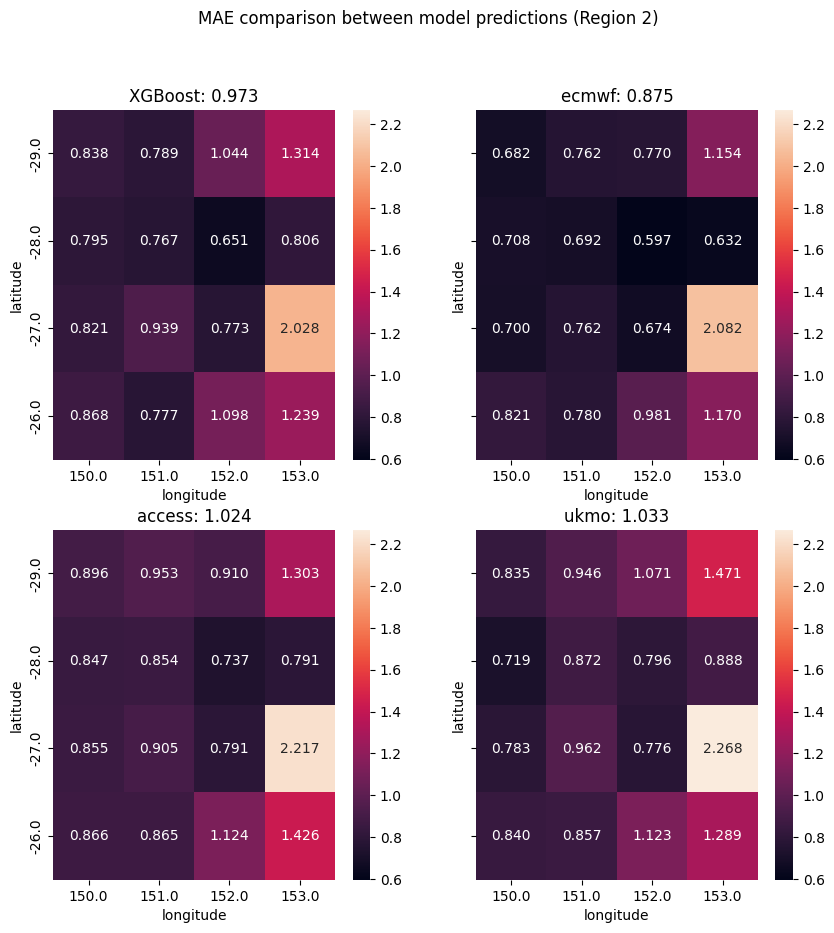

In [ ]:
fig, axes = plt.subplots(nrows=2, ncols=2, figsize = (10,10),sharey=True)

fig.suptitle("MAE comparison between model predictions (Region 2)")

vmin = result.min().min()
vmax = result.max().max()

for idx, model in enumerate(["XGBoost", "ecmwf", "access", "ukmo"]):
    j = idx % 2
    i = idx // 2
    ax = sns.heatmap(result[model].unstack(), annot=True, fmt=".3f", ax=axes[i, j], vmin=vmin, vmax=vmax)
    ax.set_title(f"{model}: {model_mae[model]:.3f}")